# Section 3 Data preprocessing and exploratory analysis

This notebook examines diabetes hospital encounters and makes the preprocessing choices visible. It covers the supplied Section 3 requirements only. EDA and fitted transforms use **development patients only**. Run from a full repository checkout or the focused ZIP, after installing `requirements.txt` (see the root README).

The sequence is: validate data -> explore -> screen unusual records -> clean and encode -> select raw features -> compare a PCA representation. Four essential figures summarize the evidence. No classifier is trained. The PDF and Markdown reference report explain the measured findings.

In [1]:
from pathlib import Path
import os, sys, json
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
candidates = [Path.cwd(), *Path.cwd().parents, Path('/content/GenoMining'), Path('/kaggle/working/GenoMining')]
ROOT = next((p for p in candidates if (p/'section3/config.json').exists() and (p/'readmission').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Set the working directory to the extracted project. See README.md.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import joblib
from scipy import sparse
from IPython.display import display, Image
from section3.run import run_section
from readmission.data import load_cohort, xy
OUT = ROOT/'section3/outputs'
def table(name):
    return pd.read_csv(OUT/'tables'/f'{name}.csv', keep_default_na=False)
def figure(name):
    display(Image(filename=str(OUT/'figures'/f'{name}.png'), width=1000))
pd.set_option('display.max_columns', 16)
print('Project:', ROOT.name)

Project: hospital-readmission


## 1 Data structure and analysis population

The original 50 columns consist of 47 candidate inputs, two identifiers and the outcome. Death/hospice encounter exclusions define the eligible cohort. Patients remain in a single partition. EDA uses only the 59,670 development encounters; the other partitions are reserved for later modeling.

In [2]:
summary = run_section()  # Set force=True only to recompute this section.
display(table('split_sizes'))
display(table('analysis_population'))
print('Raw inputs:', summary['data']['candidate_features'], '| Numeric:', summary['numeric_inputs'], '| Categorical:', summary['categorical_candidate_inputs'])

Phase data: reusing verified matching artifacts.


Section 3: reusing outputs with matching sources, data, environment and file hashes.


,split,encounters,patients
0,calibration,19746,14025
1,development,59670,41960
2,test,19927,14005


,split,encounters,patients,early_readmissions,positive_rate
0,development,59670,41960,6854,0.114865


Raw inputs: 47 | Numeric: 8 | Categorical: 39


In [3]:
cohort = load_cohort()
assert cohort.groupby('patient_nbr')['split'].nunique().max() == 1
dev = cohort.loc[cohort.split.eq('development')].reset_index(drop=True)
X, y = xy(dev)
print('Patient overlap: 0; development inputs:', X.shape)
del cohort

Patient overlap: 0; development inputs: (59670, 47)


## 2 Missingness and class imbalance

`?` is missing. The literal laboratory category `None` means the test was not performed and remains a valid category. The positive label is the existing `<30` outcome, not a reconstructed exact follow-up interval. The proportions below are percentages of encounters, not unique people.

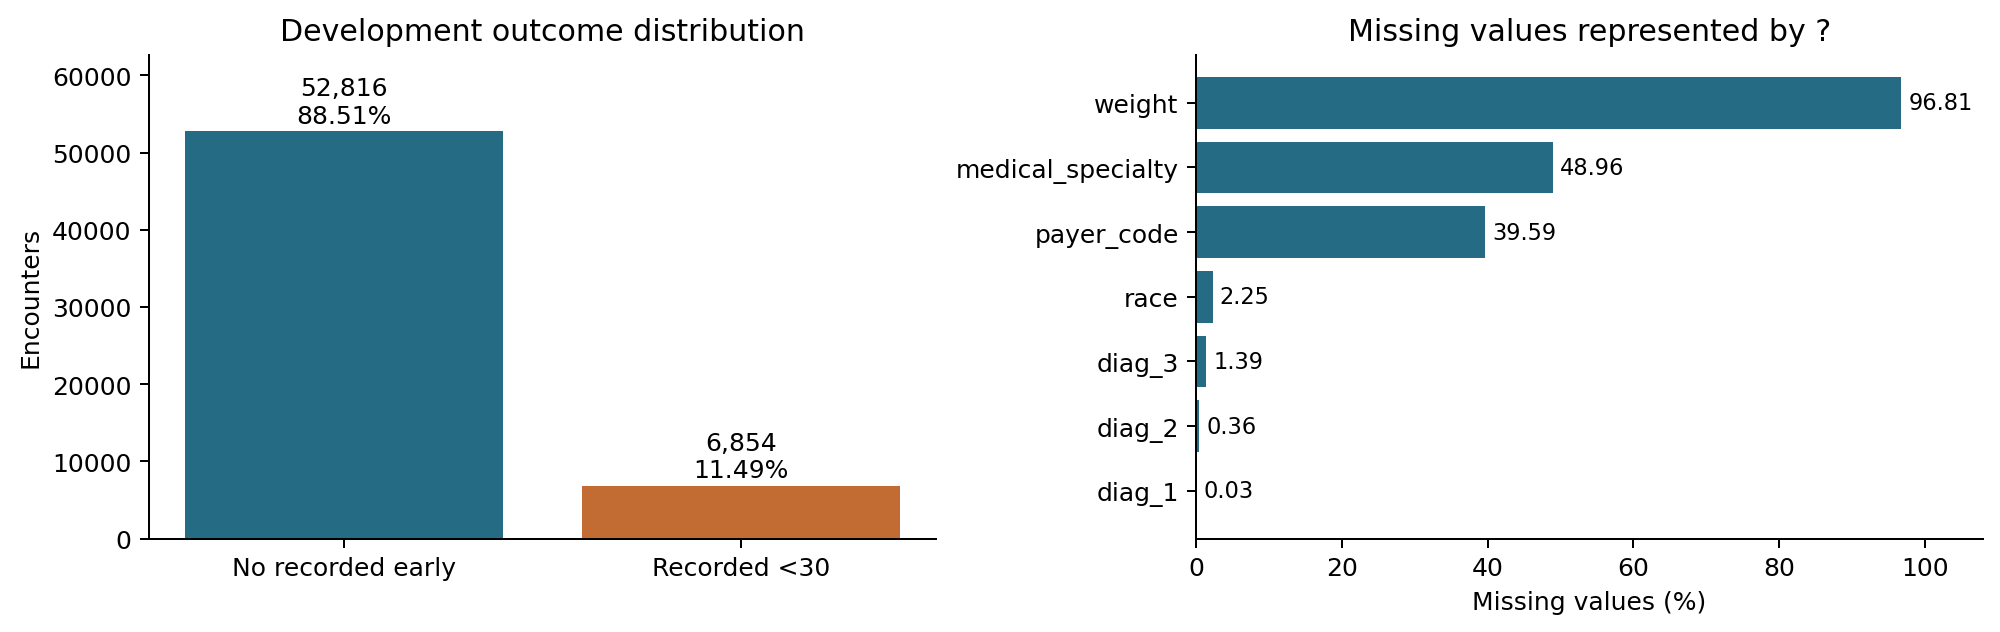

,feature,missing_count,missing_percent
0,weight,57765,96.807441
1,medical_specialty,29215,48.960952
2,payer_code,23626,39.594436
3,race,1344,2.252388
4,diag_3,831,1.392660
5,diag_2,212,0.355287
6,diag_1,15,0.025138


,feature,category,encounters,percent
0,A1Cresult,None,49453,82.877493
1,A1Cresult,>8,4986,8.355958
2,A1Cresult,Norm,2968,4.974024
3,A1Cresult,>7,2263,3.792526
4,max_glu_serum,None,56626,94.898609
5,max_glu_serum,Norm,1504,2.520530
6,max_glu_serum,>200,857,1.436233
7,max_glu_serum,>300,683,1.144629


In [4]:
figure('01_population_missingness')
display(table('missingness').head(7))
display(table('laboratory_categories'))

## 3 Distributions and associations

Histograms include every development observation. A log count axis reveals the rare tail without changing the observations. Boxplot whiskers show the 5th and 95th percentiles, and points outside them are hidden only in the figure. They are not deleted. Spearman correlation measures ranked monotonic association; it does not show causation.

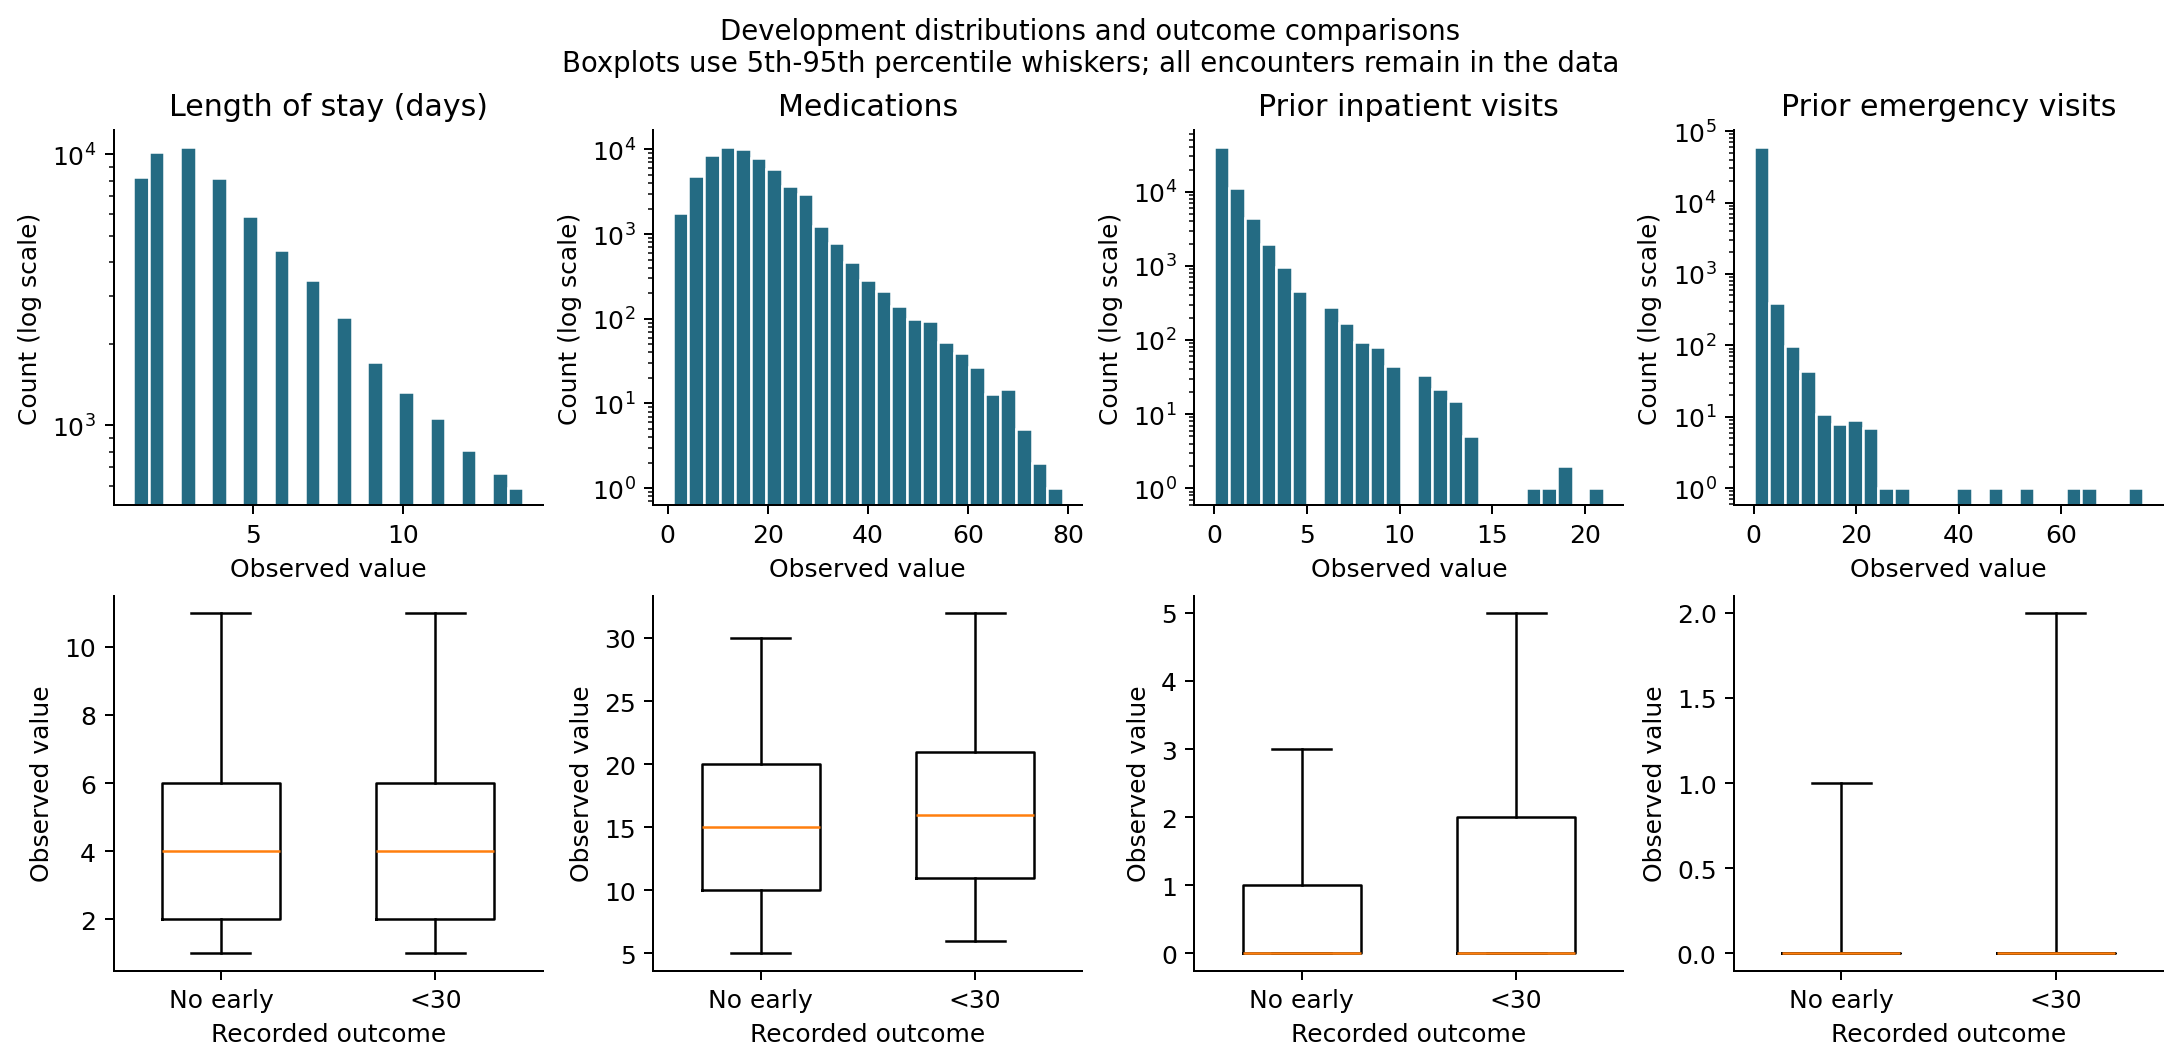

,feature,count,mean,std,min,1%,25%,50%,75%,99%,max,zero_percent,skewness
0,time_in_hospital,59670.0,4.364454,2.952804,1.0,1.0,2.0,4.0,6.0,13.0,14.0,0.000000,1.148739
1,num_lab_procedures,59670.0,42.866583,19.568948,1.0,1.0,31.0,44.0,57.0,84.0,132.0,0.000000,-0.242283
2,num_procedures,59670.0,1.329160,1.702160,0.0,0.0,0.0,1.0,2.0,6.0,6.0,46.150494,1.330644
3,num_medications,59670.0,15.968762,8.080817,1.0,3.0,10.0,15.0,20.0,43.0,79.0,0.000000,1.348824
4,number_outpatient,59670.0,0.365913,1.251955,0.0,0.0,0.0,0.0,0.0,5.0,40.0,83.623261,8.959298
5,number_emergency,59670.0,0.204961,1.031906,0.0,0.0,0.0,0.0,0.0,3.0,76.0,88.756494,25.366605
6,number_inpatient,59670.0,0.637205,1.277435,0.0,0.0,0.0,0.0,1.0,6.0,21.0,66.597955,3.630713
7,number_diagnoses,59670.0,7.411111,1.936090,1.0,2.0,6.0,8.0,9.0,9.0,16.0,0.000000,-0.862448


In [5]:
figure('02_distributions_boxplots')
display(table('numeric_summary'))

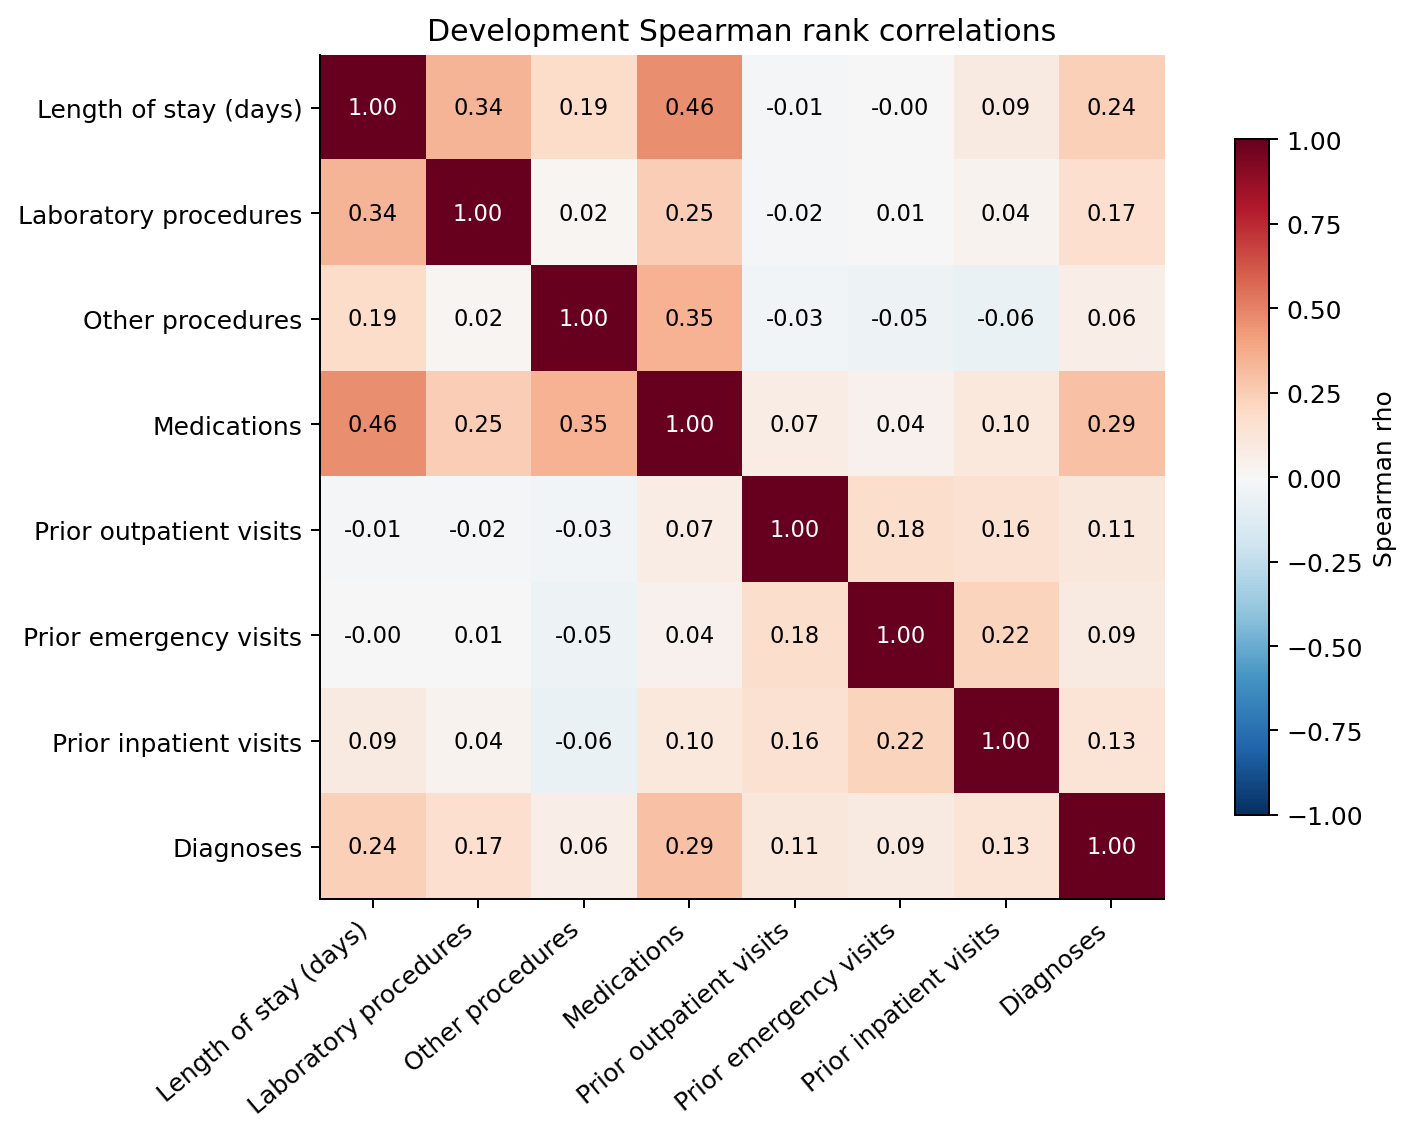

,feature_a,feature_b,spearman_rho,absolute_rho
0,time_in_hospital,num_medications,0.462843,0.462843
1,num_procedures,num_medications,0.345909,0.345909
2,time_in_hospital,num_lab_procedures,0.339938,0.339938
3,num_medications,number_diagnoses,0.291249,0.291249
4,num_lab_procedures,num_medications,0.249448,0.249448


,feature,category,encounters,early_readmissions,observed_rate
10,A1Cresult,>7,2263,238,0.105170
11,A1Cresult,>8,4986,519,0.104091
12,A1Cresult,None,49453,5783,0.116939
13,A1Cresult,Norm,2968,314,0.105795


In [6]:
figure('03_correlations')
display(table('correlation_pairs').head(5))
display(table('categorical_associations').query("feature == 'A1Cresult'"))

## 4 Outlier handling

IQR fences screen each numerical variable. Zero-heavy visit counts can have IQR zero, so every positive value can be flagged. Isolation Forest supplies a complementary multivariable screen on log1p numerical inputs. Its 3% flag setting is a review budget, not an estimate of erroneous records. All eligible encounters are retained because unusual utilization is plausible and no error labels justify deletion.

In [7]:
display(table('outlier_iqr'))
display(table('outlier_profiles'))
print('IQR any flag:', summary['iqr_any_flagged'])
print('Isolation Forest flags:', summary['isolation_flagged'])
print('Rows removed as outliers:', summary['outlier_rows_removed'])

,feature,q1,q3,iqr,lower_fence,upper_fence,zero_iqr,flagged_encounters,flagged_percent
0,time_in_hospital,2.0,6.0,4.0,-4.0,12.0,False,1256,2.104910
1,num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,False,74,0.124015
2,num_procedures,0.0,2.0,2.0,-3.0,5.0,False,2894,4.850008
3,num_medications,10.0,20.0,10.0,-5.0,35.0,False,1452,2.433384
4,number_outpatient,0.0,0.0,0.0,0.0,0.0,True,9772,16.376739
5,number_emergency,0.0,0.0,0.0,0.0,0.0,True,6709,11.243506
6,number_inpatient,0.0,1.0,1.0,-1.5,2.5,False,4140,6.938160
7,number_diagnoses,6.0,9.0,3.0,1.5,13.5,False,159,0.266466


,flagged,encounters,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
0,False,57879,4.0,44.0,1.0,15.0,0.0,0.0,0.0,8.0
1,True,1791,3.0,35.0,1.0,15.0,1.0,2.0,2.0,8.0


IQR any flag: 20162
Isolation Forest flags: 1791
Rows removed as outliers: 0


## 5 Cleaning and encoding

The saved preprocessing Pipeline contains three steps: ClinicalCleaner, RawMutualInformationSelector and ColumnTransformer. The cleaner groups diagnoses and learns exclusions from development data. The encoder median-imputes and standardizes numeric inputs; it fills missing categories with Missing and one-hot encodes them. Integer admission/discharge codes remain categorical. Inspect the learned values rather than assuming imputation changed every column.

In [8]:
full = joblib.load(OUT/'transformers/preprocessor_all.joblib')
selected = joblib.load(OUT/'transformers/preprocessor_top20.joblib')
print('Pipeline steps:', list(full.named_steps))
display(table('column_decisions').query('not retained'))
display(table('numeric_transform_audit'))
display(table('categorical_encoding_audit'))

Pipeline steps: ['clean', 'select', 'encode']


,feature,retained,reason,raw_missing_percent,distinct_after_grouping_including_missing
3,weight,False,over 95% missing,96.807441,10
27,acetohexamide,False,constant after diagnosis grouping,0.000000,1
37,examide,False,constant after diagnosis grouping,0.000000,1
38,citoglipton,False,constant after diagnosis grouping,0.000000,1
43,metformin-rosiglitazone,False,constant after diagnosis grouping,0.000000,1


,feature,missing_before,imputation_median,training_mean,training_scale,mean_after,population_std_after
0,time_in_hospital,0,4.0,4.364454,2.952780,1.200314e-16,1.0
1,num_lab_procedures,0,44.0,42.866583,19.568784,1.202695e-16,1.0
2,num_procedures,0,1.0,1.329160,1.702146,9.978797e-17,1.0
3,num_medications,0,15.0,15.968762,8.080749,7.906827e-17,1.0
4,number_outpatient,0,0.0,0.365913,1.251944,4.477360e-17,1.0
5,number_emergency,0,0.0,0.204961,1.031897,-3.572362e-17,1.0
6,number_inpatient,0,0.0,0.637205,1.277424,2.726903e-17,1.0
7,number_diagnoses,0,8.0,7.411111,1.936074,-1.238419e-16,1.0


,feature,training_categories_after_imputation,pooled_rare_categories,encoded_columns
0,race,6,0,6
1,gender,3,1,3
2,age,10,0,10
3,admission_type_id,8,2,7
4,discharge_disposition_id,21,6,16
5,admission_source_id,16,6,11
6,payer_code,17,0,17
7,medical_specialty,68,31,38
8,diag_1,10,1,10
9,diag_2,10,0,10


In [9]:
display(table('transformation_examples').head(8))
print('All inputs after encoding:', summary['all_encoded'])
print('Selected inputs after encoding:', summary['selected_encoded'])

,example_row,feature,raw_value,imputed_value,standardized_value
0,0,time_in_hospital,1.0,1.0,-1.139419
1,0,num_lab_procedures,41.0,41.0,-0.095386
2,0,num_procedures,0.0,0.0,-0.780873
3,0,num_medications,1.0,1.0,-1.852398
4,0,number_outpatient,0.0,0.0,-0.292275
5,0,number_emergency,0.0,0.0,-0.198625
6,0,number_inpatient,0.0,0.0,-0.498820
7,0,number_diagnoses,1.0,1.0,-3.311397


All inputs after encoding: {'rows': 59670, 'columns': 216, 'density': 0.19444444444444445, 'nonfinite_values': 0}
Selected inputs after encoding: {'rows': 59670, 'columns': 147, 'density': 0.1360544217687075, 'nonfinite_values': 0}


## 6 Independent feature selection and PCA

Mutual information uses development labels to rank whole raw features before one-hot expansion. It is independent of classifier fitting. The top 20 are a predeclared comparison size, not proven optimal. PCA uses no labels and creates components from all cleaned encoded inputs. It centers the representation and retains at least 95% of its variance; variance retained is not predictive accuracy. PCA and MI are separate alternatives here.

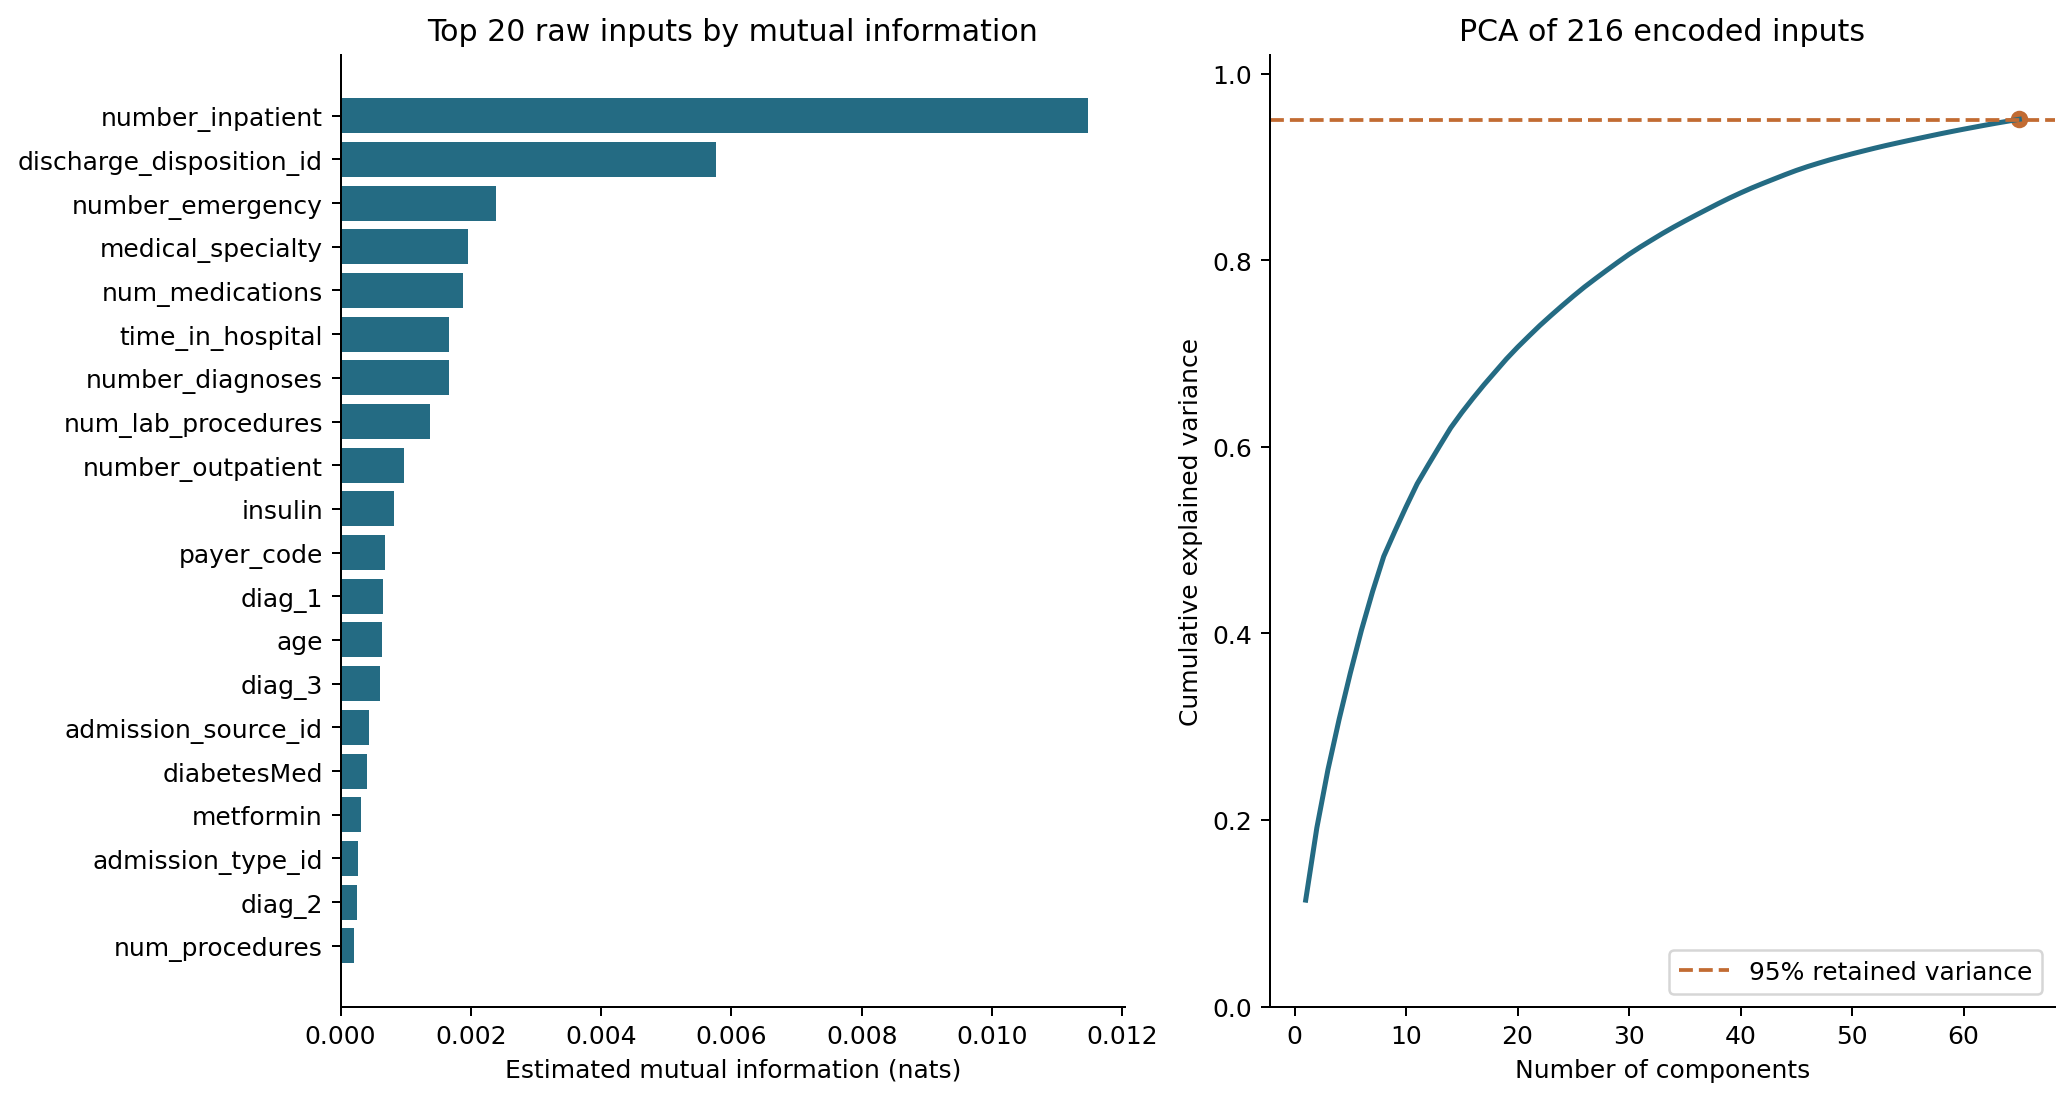

,rank,feature,mutual_information_nats,selected_top20
0,1,number_inpatient,0.011475,True
1,2,discharge_disposition_id,0.005763,True
2,3,number_emergency,0.002387,True
3,4,medical_specialty,0.001957,True
4,5,num_medications,0.001875,True
5,6,time_in_hospital,0.001663,True
6,7,number_diagnoses,0.001662,True
7,8,num_lab_procedures,0.001379,True
8,9,number_outpatient,0.000982,True
9,10,insulin,0.000820,True


,component,variance_ratio,cumulative_variance_ratio
60,61,0.002246,0.942699
61,62,0.002226,0.944925
62,63,0.002143,0.947068
63,64,0.002040,0.949108
64,65,0.001986,0.951094


PCA dimensions: 216 -> 65
Retained variance: 0.9510941505432129


In [10]:
figure('04_selection_pca')
display(table('mutual_information'))
display(table('pca_variance').tail())
print('PCA dimensions:', summary['all_encoded']['columns'], '->', summary['pca_components'])
print('Retained variance:', summary['pca_retained_variance'])

## 7 Reuse the prepared inputs safely

The sparse matrix, labels and row ledger have exactly the same development row order. They support inspection or a single development-trained fit. For later cross-validation, fit a fresh preprocessing Pipeline inside each training fold; using this already-selected full-development matrix in CV would leak validation-label information.

In [11]:
matrix = sparse.load_npz(OUT/'data/development_top20.npz')
ledger = pd.read_csv(OUT/'data/development_row_index.csv')
assert matrix.shape[0] == len(ledger) == len(dev)
np.testing.assert_array_equal(ledger.encounter_id, dev.encounter_id)
np.testing.assert_allclose(selected.transform(X.iloc[:3]).toarray(), matrix[:3].toarray(), rtol=1e-6, atol=1e-6)
print('Prepared matrix:', matrix.shape, '| row order and transform reproduction passed')

Prepared matrix: (59670, 147) | row order and transform reproduction passed


In [12]:
# Synthetic robustness check only: this category is not a real observation.
probe = X.iloc[:1].copy()
probe['age'] = 'unseen age category for test'
before = full.named_steps['encode'].named_transformers_['numeric'].named_steps['scale'].mean_.copy()
encoded_probe = full.transform(probe)
np.testing.assert_array_equal(before, full.named_steps['encode'].named_transformers_['numeric'].named_steps['scale'].mean_)
assert encoded_probe.shape[1] == summary['all_encoded']['columns']
print('Unknown-category transform succeeded without refitting the scaler.')

Unknown-category transform succeeded without refitting the scaler.


## 8 Explain the decisions

No rows were synthesized or oversampled. The original prevalence is retained; data augmentation is discussed but is not necessary for this section. Answer these before writing your final report: Why does patient separation matter? Why is None not missing? Why does standardization not remove skew? Why can IQR overflag rare visits? What does MI need that PCA does not? Why must selection be repeated within CV? The README and study guide provide worked explanations.

Read `section3/SUBMISSION_CHECKLIST.md` for the exact evidence to include. The reference report is a study aid; the team writes and verifies its final report.